# Phase 1: Simulating Quantum Noise (Before Error Correction)

## What this notebook does:
We take a qubit, hit it with different types of noise, and measure how badly the noise damages it.

## Why we do this:
This gives us the **baseline** — how bad things are WITHOUT any error correction.
Later (Phase 2), we'll add error correction codes and compare: did the code actually help?

## What we measure:
- **Fidelity** = how similar is the noisy qubit to the original? (1.0 = perfect, 0.0 = completely destroyed)
- **Physical error rate** = what fraction of measurements gave the wrong answer?

---
## Step 1: Import Libraries
These are the tools we need. Think of them as apps on your phone — each one does a specific job.

In [1]:
# === MATH & DATA TOOLS ===
import numpy as np                # For math operations (arrays, random numbers)
import pandas as pd               # For organizing results into tables
import matplotlib.pyplot as plt   # For plotting graphs

# === QISKIT CORE ===
from qiskit import QuantumCircuit                        # To build quantum circuits
from qiskit.quantum_info import Statevector, state_fidelity  # To get qubit states and compare them
from qiskit.visualization import plot_histogram           # To draw bar charts of measurement results

# === QISKIT SIMULATOR & NOISE ===
from qiskit_aer import AerSimulator                      # The virtual quantum computer
from qiskit_aer.noise import (
    NoiseModel,               # Container that holds noise settings
    pauli_error,              # To create bit-flip noise
    depolarizing_error,       # To create depolarizing noise
    amplitude_damping_error,  # To create amplitude damping noise
)

import os  # For creating output directories

# Make graphs look nice
plt.rcParams['figure.dpi'] = 110

# Fix random seed so results are reproducible (same random numbers every time)
np.random.seed(42)

# Create output directory
os.makedirs('outputs/Phase1_Noise_Simulation', exist_ok=True)

print('All libraries loaded successfully!')

All libraries loaded successfully!


---
## Step 2: Prepare Test Qubits

We need some known qubit states to test our noise on. We pick **4**:

| State | What it is | How to make it | Math |
|-------|-----------|----------------|------|
| \|0⟩ | Qubit pointing "up" (default state) | Do nothing | [1, 0] |
| \|1⟩ | Qubit pointing "down" | Apply X gate | [0, 1] |
| \|+⟩ | Superposition with + sign | Apply H gate | (\|0⟩ + \|1⟩)/√2 |
| \|−⟩ | Superposition with − sign | Apply X then H | (\|0⟩ − \|1⟩)/√2 |

**Why these 4?** Because different noise types affect different states differently.
- \|0⟩ and \|1⟩ are **computational basis** states (bit values)
- \|+⟩ and \|−⟩ are **superposition basis** states (phase matters)

Testing all 4 reveals which noise types have blind spots and which don't.

In [2]:
def make_qubit(state_name):
    """
    Create a 1-qubit circuit that prepares the given state.
    
    state_name can be:
      '0' → |0⟩  (do nothing, qubit starts as 0 by default)
      '1' → |1⟩  (apply X gate to flip 0 to 1)
      '+' → |+⟩  (apply H gate to create superposition with + sign)
      '-' → |−⟩  (apply X then H to create superposition with − sign)
    """
    circuit = QuantumCircuit(1)   # Create a circuit with 1 qubit
    
    if state_name == '1':
        circuit.x(0)             # X gate: |0⟩ → |1⟩
    elif state_name == '+':
        circuit.h(0)             # H gate: |0⟩ → |+⟩ = (|0⟩ + |1⟩)/√2
    elif state_name == '-':
        circuit.x(0)             # First flip: |0⟩ → |1⟩
        circuit.h(0)             # Then Hadamard: |1⟩ → |−⟩ = (|0⟩ − |1⟩)/√2
    # If state_name == '0', we do nothing (qubit is already |0⟩)
    
    return circuit


# Test it: print what each state looks like mathematically
for name in ['0', '1', '+', '-']:
    state_vector = Statevector(make_qubit(name))
    print(f'|{name}⟩  →  {state_vector.data.round(3)}')
    
# Expected output:
# |0⟩ → [1, 0]            100% chance of measuring 0
# |1⟩ → [0, 1]            100% chance of measuring 1  
# |+⟩ → [0.707,  0.707]   50/50, with + sign (positive interference)
# |−⟩ → [0.707, -0.707]   50/50, with − sign (negative interference)

|0⟩  →  [1.+0.j 0.+0.j]
|1⟩  →  [0.+0.j 1.+0.j]
|+⟩  →  [0.707+0.j 0.707+0.j]
|-⟩  →  [ 0.707+0.j -0.707+0.j]


---
## Step 3: Create Noise Models

Now we build the 3 types of noise our project tests:

### Noise Type 1: Bit-Flip
- With probability `p`, the qubit flips: 0→1 or 1→0
- Like someone randomly flipping your light switch
- **Formula:** E(ρ) = (1−p)ρ + p·XρX

### Noise Type 2: Depolarizing  
- With probability `p`, the qubit is replaced by the maximally mixed state I/2 (total scrambling); with probability `1−p` it's left alone
- Like the qubit getting scrambled in a random direction
- **Formula:** E(ρ) = (1−p)ρ + p·I/2 = (1 − 3p/4)ρ + (p/4)(XρX + YρY + ZρZ) — note X, Y, Z each fire with probability **p/4**, not p/3

### Noise Type 3: Amplitude Damping
- The qubit loses energy: |1⟩ decays toward |0⟩
- Like a ball rolling downhill — only goes one way
- **Formula:** E(ρ) = K₀ρK₀† + K₁ρK₁†  (Kraus operators)

**Important:** We attach noise to the `id` (identity/idle) gate. This gate does nothing by itself — it just represents the qubit sitting there doing nothing while noise hits it.

In [3]:
def make_bit_flip_noise(p):
    """
    Bit-Flip noise: with probability p, apply X gate (flip the qubit).
    With probability (1-p), apply I gate (do nothing).
    """
    error = pauli_error([
        ('X', p),       # p chance of flipping
        ('I', 1 - p)    # (1-p) chance of doing nothing
    ])
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])  # Attach to idle gate
    return noise_model


def make_depolarizing_noise(p):
    """
    Depolarizing noise: mixes in the maximally mixed state I/2 with probability p
    (Qiskit's convention), i.e. E(rho) = (1-p)*rho + p*I/2. Expanded in the Pauli
    basis this is (1 - 3p/4)*rho + (p/4)*(X*rho*X + Y*rho*Y + Z*rho*Z) — so each of
    X, Y, Z actually fires with probability p/4, NOT p/3 as you might first guess.
    """
    error = depolarizing_error(p, 1)   # p = total error probability, 1 = single qubit
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


def make_amplitude_damping_noise(gamma):
    """
    Amplitude Damping: qubit in |1⟩ decays to |0⟩ with probability gamma.
    Qubit in |0⟩ is unaffected (it's already at the lowest energy).
    """
    error = amplitude_damping_error(gamma)   # gamma = decay probability
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


# Store all 3 noise makers in a dictionary for easy looping later
noise_makers = {
    'Bit-Flip':          make_bit_flip_noise,
    'Depolarizing':      make_depolarizing_noise,
    'Amplitude Damping': make_amplitude_damping_noise,
}

print('All 3 noise models ready!')

All 3 noise models ready!


---
## Step 4: Sanity Check — See Noise in Action

Before doing the full experiment, let's do ONE simple test to see if noise actually works:

1. Prepare |0⟩
2. Apply 30% bit-flip noise (so there's a 30% chance it flips to |1⟩)
3. Measure 2000 times
4. Compare with the noiseless case

**Expected:** Without noise, we should get 0 every time. With 30% noise, we should get 1 about 30% of the time.

Without noise: {'0': 2000}
With 30% noise: {'1': 630, '0': 1370}


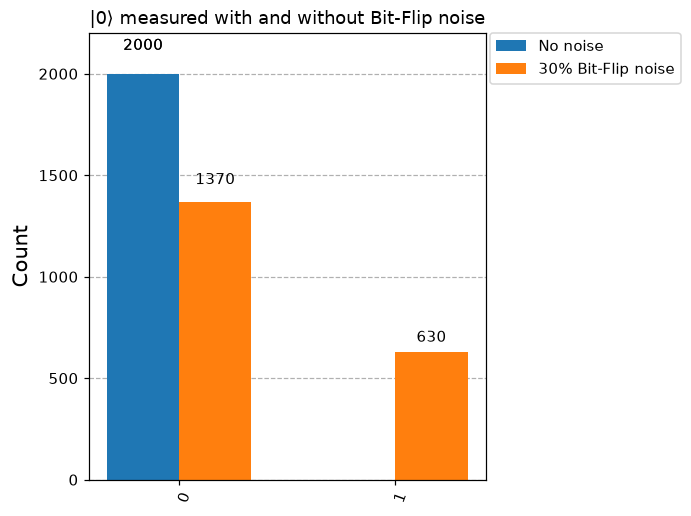

In [4]:
# Build the circuit: prepare |0⟩, add idle gate (where noise will attach), measure
demo_circuit = make_qubit('0')     # Start with |0⟩
demo_circuit.id(0)                 # Idle gate — noise attaches here
demo_circuit.measure_all()         # Measure the qubit

# Run WITHOUT noise (perfect simulator)
perfect_sim = AerSimulator()
perfect_results = perfect_sim.run(demo_circuit, shots=2000).result().get_counts()

# Run WITH 30% bit-flip noise
noisy_sim = AerSimulator(noise_model=make_bit_flip_noise(0.30))
noisy_results = noisy_sim.run(demo_circuit, shots=2000).result().get_counts()

# Print raw numbers
print(f'Without noise: {perfect_results}')   # Should be all 0s
print(f'With 30% noise: {noisy_results}')     # Should be ~70% 0s, ~30% 1s

# Plot side by side
plot_histogram(
    [perfect_results, noisy_results],
    legend=['No noise', '30% Bit-Flip noise'],
    title='|0⟩ measured with and without Bit-Flip noise',
)

---
## Step 5: The Main Experiment — Fidelity vs Noise

Now the real experiment. For EVERY combination of:
- 3 noise types (Bit-Flip, Depolarizing, Amplitude Damping)
- **4 qubit states** (|0⟩, |1⟩, |+⟩, |−⟩)
- 10 noise levels (0% to 50%)

That's 3 × 4 × 10 = **120 experiments**.

For each one, we:
1. Prepare the qubit in the test state
2. Apply noise at the given probability
3. Get the resulting noisy state (as a density matrix — a way to represent mixed/noisy states)
4. Compare it to the ideal state using **fidelity**

**Note:** We use `save_density_matrix()` instead of `measure_all()` here. Why?
Because measurement collapses the qubit to 0 or 1 — we'd lose the quantum information.
Density matrix lets us see the FULL noisy state without collapsing it.

In [5]:
# Noise levels to test: from 0% (no noise) to 50% (extreme noise)
noise_levels = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

# The 4 test states (now including |−⟩)
test_states = ['0', '1', '+', '-']

# Display label per state — note '-' maps to the proper Unicode minus sign '−' (U+2212),
# matching the character used everywhere else in this notebook (legends, markdown, etc.)
# so that string comparisons like `results_table.state == '|−⟩'` actually match instead
# of silently comparing against a plain ASCII hyphen and returning empty results.
STATE_LABELS = {'0': '0', '1': '1', '+': '+', '-': '−'}


def measure_fidelity(state_name, noise_type, noise_prob):
    """
    Prepare a qubit, hit it with noise, and measure how damaged it is.
    
    Returns: fidelity (float between 0 and 1)
      1.0 = qubit is perfectly intact
      0.0 = qubit is completely destroyed
    """
    # STEP A: Build the circuit
    circuit = make_qubit(state_name)     # Prepare the qubit
    circuit.id(0)                        # Add idle gate (noise attaches here)
    circuit.save_density_matrix()        # Save the full quantum state (don't collapse it)
    
    # STEP B: Create the noisy simulator
    noise_model = noise_makers[noise_type](noise_prob)   # Build noise with given probability
    simulator = AerSimulator(method='density_matrix', noise_model=noise_model)
    
    # STEP C: Run the simulation
    result = simulator.run(circuit).result()
    noisy_state = result.data(0)['density_matrix']   # Extract the noisy density matrix
    
    # STEP D: Compare noisy state with the ideal (noiseless) state
    ideal_state = Statevector(make_qubit(state_name))  # What the state SHOULD be
    fidelity = state_fidelity(ideal_state, noisy_state) # How close are they? (0 to 1)
    
    return fidelity


# === RUN ALL 120 EXPERIMENTS ===
all_results = []   # We'll store every result here

for noise_type in noise_makers:          # Loop over 3 noise types
    for state_name in test_states:        # Loop over 4 states
        for p in noise_levels:             # Loop over 10 noise levels
            fid = measure_fidelity(state_name, noise_type, p)
            all_results.append({
                'noise_type': noise_type,
                'state': f'|{STATE_LABELS[state_name]}⟩',
                'noise_prob': p,
                'fidelity': round(fid, 4)
            })

# Convert to a nice table
results_table = pd.DataFrame(all_results)

# Show first 10 rows
print(f'Total experiments: {len(results_table)}')
results_table.head(10)

Total experiments: 120


,noise_type,state,noise_prob,fidelity
0,Bit-Flip,|0⟩,0.00,1.00
1,Bit-Flip,|0⟩,0.01,0.99
2,Bit-Flip,|0⟩,0.02,0.98
3,Bit-Flip,|0⟩,0.05,0.95
4,Bit-Flip,|0⟩,0.10,0.90
5,Bit-Flip,|0⟩,0.15,0.85
6,Bit-Flip,|0⟩,0.20,0.80
7,Bit-Flip,|0⟩,0.30,0.70
8,Bit-Flip,|0⟩,0.40,0.60
9,Bit-Flip,|0⟩,0.50,0.50


### Plot the Results

Three graphs side by side — one per noise type. Each graph shows how fidelity drops as noise increases, for all 4 test states.

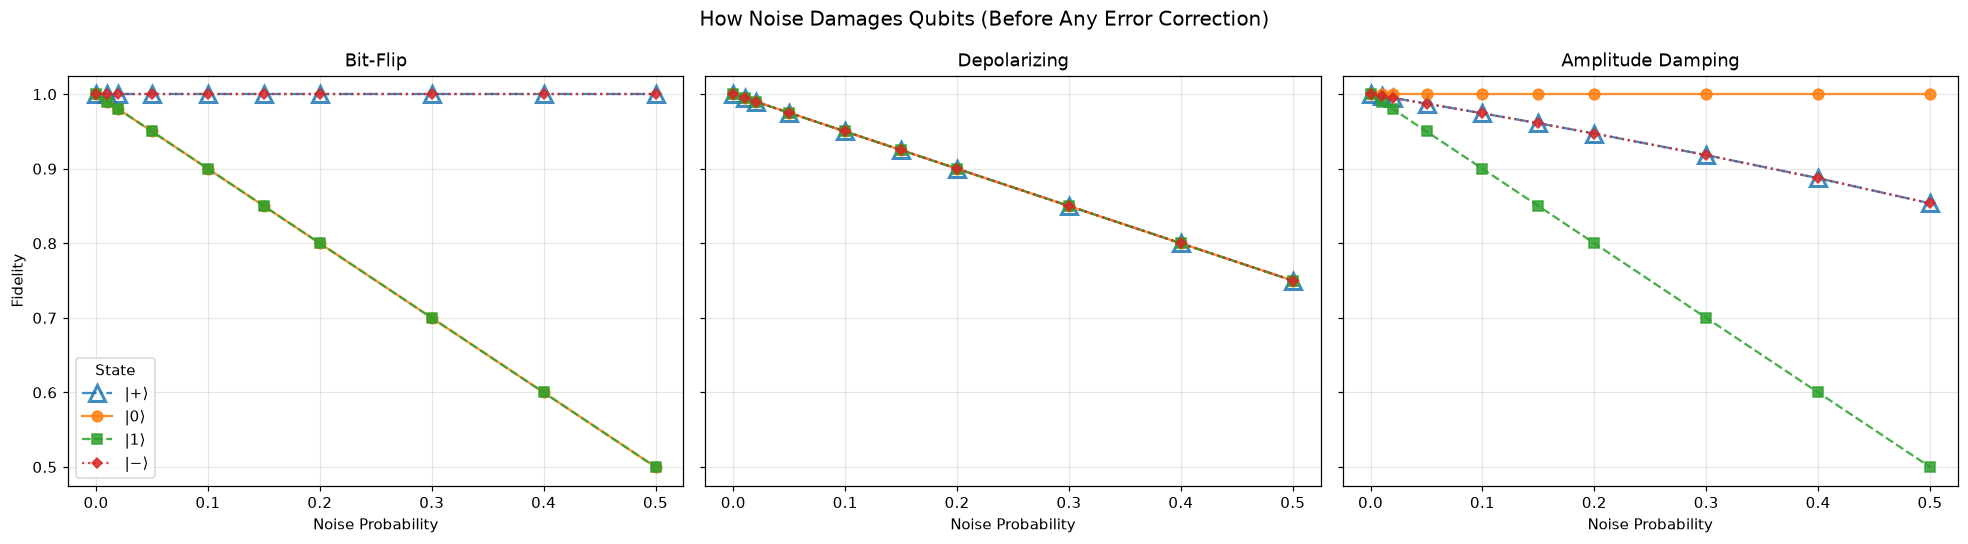


Key observations:
• Bit-Flip: Both |+⟩ AND |−⟩ stay at 1.0 — bit-flip noise cannot hurt superposition states
  (Because X|+⟩ = |+⟩ and X|−⟩ = −|−⟩, and global phase does not affect fidelity)
  These two curves overlap exactly — look for the hollow triangle (|+⟩) vs dotted diamond (|−⟩)
• Amplitude Damping: |0⟩ stays at 1.0 — already at lowest energy, cannot decay further
• Depolarizing: ALL states get damaged — no state is immune


In [6]:
# Distinct line style + marker per state, so that curves which end up perfectly
# coincident (e.g. |+⟩ and |−⟩ have identical fidelity under Bit-Flip and Depolarizing
# noise) don't just silently hide one another under a single solid line.
STATE_STYLES = {
    '|0⟩': dict(linestyle='-',  marker='o', markersize=7),
    '|1⟩': dict(linestyle='--', marker='s', markersize=7),
    '|+⟩': dict(linestyle='-.', marker='^', markersize=10, markerfacecolor='none', markeredgewidth=2),
    '|−⟩': dict(linestyle=':',  marker='D', markersize=5),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    # Filter data for this noise type
    subset = results_table[results_table.noise_type == noise_type]
    
    # Plot each state as a separate line, using a distinct style per state
    for state_name, group in subset.groupby('state'):
        ax.plot(group.noise_prob, group.fidelity, label=state_name, alpha=0.85, **STATE_STYLES[state_name])
    
    ax.set_title(noise_type)
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Fidelity')
axes[0].legend(title='State')
fig.suptitle('How Noise Damages Qubits (Before Any Error Correction)', fontsize=13)
fig.tight_layout()
fig.savefig('outputs/Phase1_Noise_Simulation/fidelity_vs_noise_probability.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey observations:')
print('• Bit-Flip: Both |+⟩ AND |−⟩ stay at 1.0 — bit-flip noise cannot hurt superposition states')
print('  (Because X|+⟩ = |+⟩ and X|−⟩ = −|−⟩, and global phase does not affect fidelity)')
print('  These two curves overlap exactly — look for the hollow triangle (|+⟩) vs dotted diamond (|−⟩)')
print('• Amplitude Damping: |0⟩ stays at 1.0 — already at lowest energy, cannot decay further')
print('• Depolarizing: ALL states get damaged — no state is immune')

---
## Step 6: Noise Dangerousness Analysis

### Why does depolarizing noise have a gentler slope than pure bit-flip noise?

Let's compute the **effective damage** each noise type does to each state.

**Important:** Qiskit's `depolarizing_error(p, 1)` does **not** mean "apply X, Y, or Z each with probability p/3". It means: with probability `p`, replace the qubit with the **maximally mixed state** `I/2`, and with probability `1−p`, leave it alone. Since `I/2 = (ρ + XρX + YρY + ZρZ)/4`, this expands to:

E(ρ) = (1 − 3p/4)·ρ + (p/4)·(XρX + YρY + ZρZ)

So each of X, Y, Z actually occurs with probability **p/4** (not p/3), and "do nothing" happens with probability **1 − 3p/4** (not 1−p). Not all three errors damage every state:

| State | Bit-Flip (X only) | Phase-Flip (Z only) | Which errors in depolarizing actually hurt? | Effective damage |
|-------|-------------------|---------------------|---------------------------------------------|------------------|
| \|0⟩ | Damaged (fidelity = 1−p) | Immune (Z\|0⟩ = \|0⟩) | X hurts (p/4), Y hurts (p/4), Z doesn't | p/2 |
| \|1⟩ | Damaged (fidelity = 1−p) | Immune (Z\|1⟩ = −\|1⟩) | X hurts (p/4), Y hurts (p/4), Z doesn't | p/2 |
| \|+⟩ | Immune (X\|+⟩ = \|+⟩) | Damaged (fidelity = 1−p) | Z hurts (p/4), Y hurts (p/4), X doesn't | p/2 |
| \|−⟩ | Immune (X\|−⟩ = −\|−⟩) | Damaged (fidelity = 1−p) | Z hurts (p/4), Y hurts (p/4), X doesn't | p/2 |

**Result:** Pure bit-flip or pure phase-flip noise damages vulnerable states with full probability `p`.
Depolarizing noise only damages with `p/2` because (a) one of the three error types is always harmless to any given state, and (b) Qiskit spreads the total probability `p` over the three Pauli errors at `p/4` each — not `p/3` — reserving the rest as a "do nothing" allowance.

**Analogy:** Imagine 3 assassins (X, Y, Z), each dispatched with probability p/4 (the remaining probability is a stand-down order). For |0⟩, assassin Z is actually friendly — he does nothing. So only 2 of the 4 "probability slices" (p/4 + p/4 = p/2) are dangerous. That's why the slope is even gentler than a naive p/3-per-error picture would suggest.

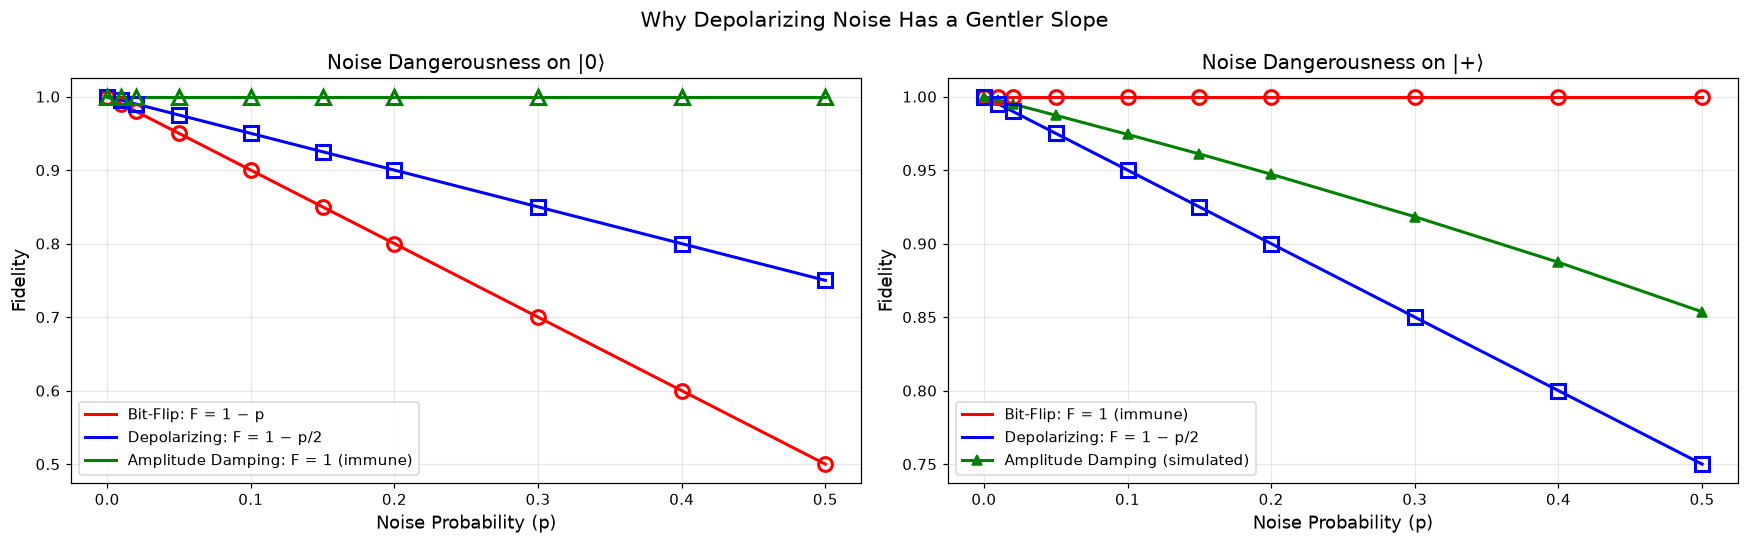

Lines = theoretical prediction, hollow dots = simulation results
(hollow markers so the line stays visible through them when they coincide).
They now match — proving the corrected math (F = 1 − p/2 for depolarizing) is right.


In [7]:
# === THEORETICAL FIDELITY FORMULAS ===
# Let's compute the exact theoretical fidelity for each noise type on each state
# and compare with our simulation results to prove the math is correct.

p_values = np.linspace(0, 0.50, 100)   # Smooth curve from 0% to 50%

# Theoretical fidelity formulas:
# Bit-Flip on |0⟩ or |1⟩:  F = 1 - p       (full damage)
# Bit-Flip on |+⟩ or |−⟩:  F = 1.0          (immune)
# Depolarizing on any state: F = 1 - p/2     (reduced damage — see Step 6 for why)
# Amplitude Damping on |0⟩:  F = 1.0          (immune)
# Amplitude Damping on |1⟩:  F = 1 - gamma    (full decay)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- LEFT PLOT: Compare slopes for |0⟩ across noise types ---
ax = axes[0]
ax.plot(p_values, 1 - p_values, 'r-', linewidth=2, label='Bit-Flip: F = 1 − p')
ax.plot(p_values, 1 - p_values/2, 'b-', linewidth=2, label='Depolarizing: F = 1 − p/2')
ax.plot(p_values, np.ones_like(p_values), 'g-', linewidth=2, label='Amplitude Damping: F = 1 (immune)')

# Overlay simulation data points for |0⟩. Markers are hollow (facecolor='none') so
# that where prediction and simulation coincide, the theory line stays visible
# right through the middle of the marker instead of being hidden underneath it.
for noise_type, color, marker in [('Bit-Flip', 'red', 'o'), ('Depolarizing', 'blue', 's'), ('Amplitude Damping', 'green', '^')]:
    subset = results_table[(results_table.noise_type == noise_type) & (results_table.state == '|0⟩')]
    ax.plot(subset.noise_prob, subset.fidelity, marker, color=color, markersize=9,
            markerfacecolor='none', markeredgewidth=2)

ax.set_xlabel('Noise Probability (p)', fontsize=12)
ax.set_ylabel('Fidelity', fontsize=12)
ax.set_title('Noise Dangerousness on |0⟩', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# --- RIGHT PLOT: Compare slopes for |+⟩ across noise types ---
ax = axes[1]
ax.plot(p_values, np.ones_like(p_values), 'r-', linewidth=2, label='Bit-Flip: F = 1 (immune)')
ax.plot(p_values, 1 - p_values/2, 'b-', linewidth=2, label='Depolarizing: F = 1 − p/2')

# For amplitude damping on |+⟩, the formula is more complex:
# F = (1 + sqrt(1 - gamma))^2 / 4 + (1 - sqrt(1 - gamma))^2 / 4 ... 
# We just use simulation data points here
subset_ad = results_table[(results_table.noise_type == 'Amplitude Damping') & (results_table.state == '|+⟩')]
ax.plot(subset_ad.noise_prob, subset_ad.fidelity, '^-', color='green', linewidth=2, label='Amplitude Damping (simulated)')

# Overlay simulation data points for |+⟩ (hollow markers, same reasoning as above)
for noise_type, color, marker in [('Bit-Flip', 'red', 'o'), ('Depolarizing', 'blue', 's')]:
    subset = results_table[(results_table.noise_type == noise_type) & (results_table.state == '|+⟩')]
    ax.plot(subset.noise_prob, subset.fidelity, marker, color=color, markersize=9,
            markerfacecolor='none', markeredgewidth=2)

ax.set_xlabel('Noise Probability (p)', fontsize=12)
ax.set_ylabel('Fidelity', fontsize=12)
ax.set_title('Noise Dangerousness on |+⟩', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

fig.suptitle('Why Depolarizing Noise Has a Gentler Slope', fontsize=14)
fig.tight_layout()
fig.savefig('outputs/Phase1_Noise_Simulation/noise_dangerousness_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('Lines = theoretical prediction, hollow dots = simulation results')
print('(hollow markers so the line stays visible through them when they coincide).')
print('They now match — proving the corrected math (F = 1 − p/2 for depolarizing) is right.')

In [8]:
# === NUMERICAL PROOF: Slope comparison at p = 0.20 ===
p_test = 0.20

print('Fidelity at p = 0.20 (20% noise probability)')
print('=' * 65)
print(f'{"State":<8} {"Bit-Flip":<18} {"Depolarizing":<18} {"Amp. Damping":<18}')
print('-' * 65)

for state in ['|0⟩', '|1⟩', '|+⟩', '|−⟩']:
    vals = []
    for noise_type in ['Bit-Flip', 'Depolarizing', 'Amplitude Damping']:
        row = results_table[
            (results_table.noise_type == noise_type) & 
            (results_table.state == state) & 
            (results_table.noise_prob == p_test)
        ]
        if len(row) > 0:
            vals.append(f'{row.fidelity.values[0]:.4f}')
        else:
            vals.append('N/A')
    print(f'{state:<8} {vals[0]:<18} {vals[1]:<18} {vals[2]:<18}')

print()
print('Key takeaway:')
print(f'  Bit-Flip on |0⟩:     F = 1 - p    = 1 - {p_test} = {1 - p_test:.2f}  (steep slope)')
print(f'  Depolarizing on |0⟩: F = 1 - p/2  = 1 - {p_test/2:.4f} = {1 - p_test/2:.4f}  (gentler slope)')
print(f'  Difference: depolarizing is {((1-p_test/2) - (1-p_test))*100:.1f}% points higher in fidelity')
print()
print("Why? Qiskit's depolarizing_error(p) fires X, Y, or Z each with probability p/4")
print('(not p/3) — the rest of p is a "do nothing" allowance. Only X and Y damage |0⟩,')
print('so the effective damage is p/4 + p/4 = p/2. Z does nothing to |0⟩ because Z|0⟩ = |0⟩.')

Fidelity at p = 0.20 (20% noise probability)
State    Bit-Flip           Depolarizing       Amp. Damping      
-----------------------------------------------------------------
|0⟩      0.8000             0.9000             1.0000            
|1⟩      0.8000             0.9000             0.8000            
|+⟩      1.0000             0.9000             0.9472            
|−⟩      1.0000             0.9000             0.9472            

Key takeaway:
  Bit-Flip on |0⟩:     F = 1 - p    = 1 - 0.2 = 0.80  (steep slope)
  Depolarizing on |0⟩: F = 1 - p/2  = 1 - 0.1000 = 0.9000  (gentler slope)
  Difference: depolarizing is 10.0% points higher in fidelity

Why? Qiskit's depolarizing_error(p) fires X, Y, or Z each with probability p/4
(not p/3) — the rest of p is a "do nothing" allowance. Only X and Y damage |0⟩,
so the effective damage is p/4 + p/4 = p/2. Z does nothing to |0⟩ because Z|0⟩ = |0⟩.


---
## Step 7: |+⟩ vs |−⟩ Under Bit-Flip Noise

Your professor asked: if |+⟩ is immune to bit-flip noise, is |−⟩ also immune?

Let's check the math:
- X|+⟩ = X · (|0⟩ + |1⟩)/√2 = (|1⟩ + |0⟩)/√2 = |+⟩  → **same state**
- X|−⟩ = X · (|0⟩ − |1⟩)/√2 = (|1⟩ − |0⟩)/√2 = −|−⟩  → **differs by global phase (−1)**

Global phase has no physical effect — it doesn't change any measurement outcome or fidelity.
So |−⟩ is also immune to bit-flip noise.

**However**, |−⟩ behaves differently from |+⟩ under amplitude damping, because the
interference between the |0⟩ and |1⟩ components (+ vs −) affects how the decay plays out.

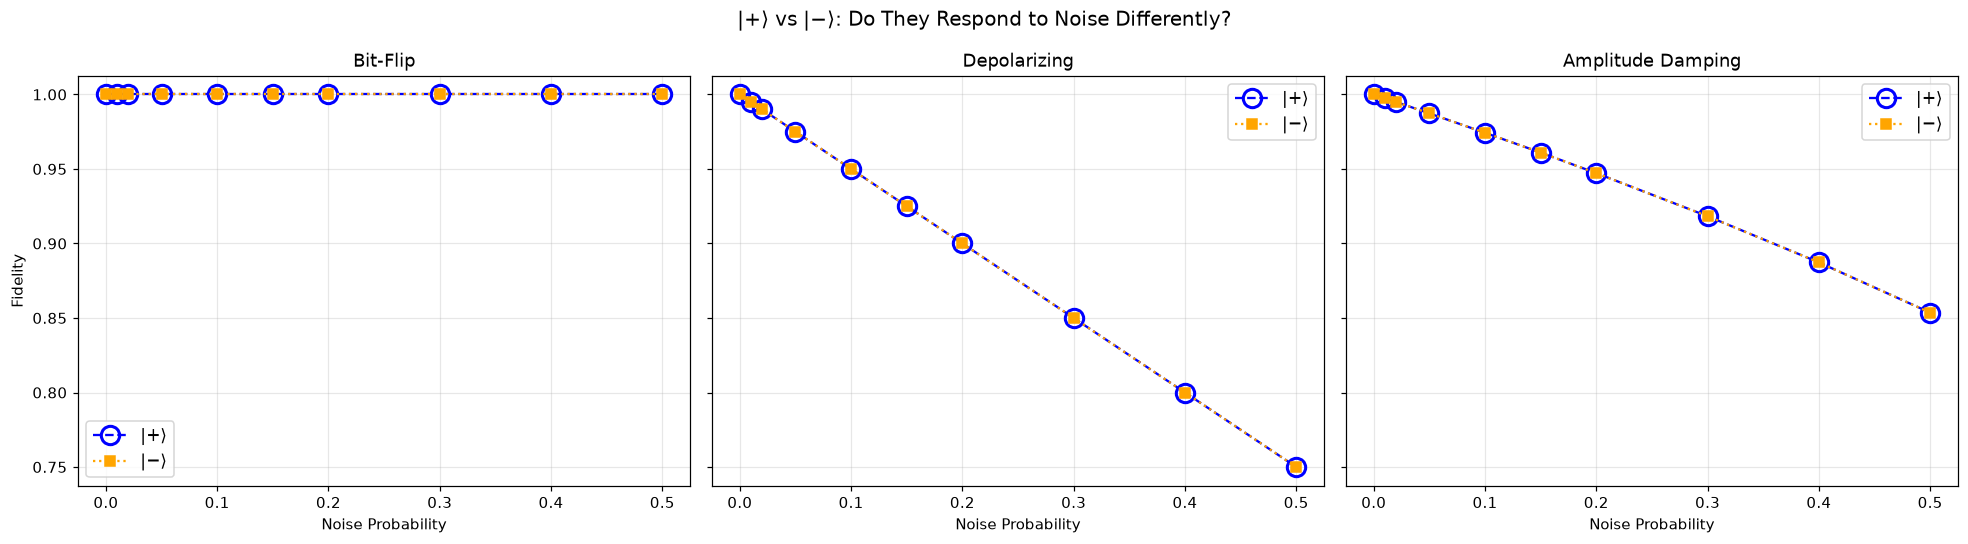

Observations:
• Bit-Flip: Both |+⟩ and |−⟩ are immune (both stay at 1.0) — curves overlap exactly,
  shown as a small orange square nested inside a hollow blue circle
• Depolarizing: Both drop identically (same effective damage p/2) — same overlap pattern
• Amplitude Damping: Check if there is any difference in how they decay


In [9]:
# Direct comparison: |+⟩ vs |−⟩ under each noise type.
# Under Bit-Flip and Depolarizing these two curves have IDENTICAL fidelity at every
# point, so a plain solid line would hide one completely behind the other. We give
# |+⟩ a large hollow marker + dashed line and |−⟩ a small filled marker + dotted
# line, so both remain visible (as a "ring around a dot") even when they trace the
# exact same path.
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

state_styles = [
    ('|+⟩', 'blue',   dict(linestyle='--', marker='o', markersize=12, markerfacecolor='none', markeredgewidth=2)),
    ('|−⟩', 'orange', dict(linestyle=':',  marker='s', markersize=6)),
]

for ax, noise_type in zip(axes, noise_makers):
    for state_name, color, style in state_styles:
        subset = results_table[
            (results_table.noise_type == noise_type) & 
            (results_table.state == state_name)
        ]
        ax.plot(subset.noise_prob, subset.fidelity, color=color, label=state_name, **style)
    
    ax.set_title(noise_type)
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=11)

axes[0].set_ylabel('Fidelity')
fig.suptitle('|+⟩ vs |−⟩: Do They Respond to Noise Differently?', fontsize=13)
fig.tight_layout()
fig.savefig('outputs/Phase1_Noise_Simulation/plus_vs_minus_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observations:')
print('• Bit-Flip: Both |+⟩ and |−⟩ are immune (both stay at 1.0) — curves overlap exactly,')
print('  shown as a small orange square nested inside a hollow blue circle')
print('• Depolarizing: Both drop identically (same effective damage p/2) — same overlap pattern')
print('• Amplitude Damping: Check if there is any difference in how they decay')

---
## Step 8: Verify Our Noise is Correct

A sanity check: if we inject 5% bit-flip noise, do we actually see ~5% of measurements flip?

We prepare |0⟩, apply bit-flip noise at each probability, measure 5000 times, and count how many times we got |1⟩ (which means a flip happened). The measured flip rate should match the injected probability.

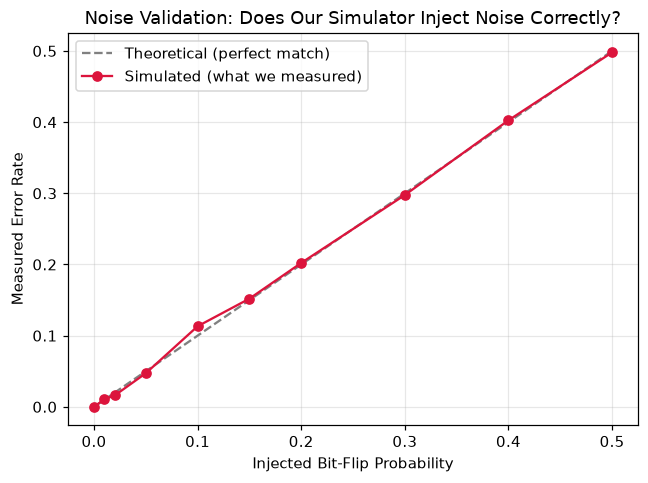

If the red dots sit on the gray dashed line, our noise is working correctly!



,injected_probability,measured_error_rate
0,0.00,0.0000
1,0.01,0.0106
2,0.02,0.0160
3,0.05,0.0472
4,0.10,0.1132
5,0.15,0.1520
6,0.20,0.2022
7,0.30,0.2976
8,0.40,0.4026
9,0.50,0.4980


In [10]:
num_shots = 5000    # Measure each experiment 5000 times for statistical accuracy
validation_results = []

for p in noise_levels:
    # Build circuit: prepare |0⟩ → idle gate → measure
    circuit = make_qubit('0')
    circuit.id(0)
    circuit.measure_all()
    
    # Run with bit-flip noise at probability p
    sim = AerSimulator(noise_model=make_bit_flip_noise(p))
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    # Count how many times we got '1' (meaning a flip happened)
    # counts.get('1', 0) means: get the count for '1', or 0 if no flips happened
    flips = counts.get('1', 0)
    measured_error_rate = flips / num_shots
    
    validation_results.append({
        'injected_probability': p,
        'measured_error_rate': measured_error_rate
    })

validation_table = pd.DataFrame(validation_results)

# Plot: if noise is working correctly, the dots should fall on the diagonal line
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(validation_table.injected_probability, validation_table.injected_probability,
        '--', color='gray', label='Theoretical (perfect match)')
ax.plot(validation_table.injected_probability, validation_table.measured_error_rate,
        'o-', color='crimson', label='Simulated (what we measured)')
ax.set_xlabel('Injected Bit-Flip Probability')
ax.set_ylabel('Measured Error Rate')
ax.set_title('Noise Validation: Does Our Simulator Inject Noise Correctly?')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('outputs/Phase1_Noise_Simulation/physical_error_rate_validation.png', dpi=150, bbox_inches='tight')
plt.show()

print('If the red dots sit on the gray dashed line, our noise is working correctly!')
print()
validation_table

---
## Step 9: Save Results

Save everything to CSV files so we can use these baselines in Phase 2.

In [11]:
results_table.to_csv('outputs/Phase1_Noise_Simulation/noise_fidelity_results.csv', index=False)
validation_table.to_csv('outputs/Phase1_Noise_Simulation/physical_error_rate_results.csv', index=False)

print('Saved: outputs/Phase1_Noise_Simulation/noise_fidelity_results.csv')
print('Saved: outputs/Phase1_Noise_Simulation/physical_error_rate_results.csv')
print()
print('Phase 1 complete!')
print('Next: Phase 2 — add error correction codes and compare.')

Saved: outputs/Phase1_Noise_Simulation/noise_fidelity_results.csv
Saved: outputs/Phase1_Noise_Simulation/physical_error_rate_results.csv

Phase 1 complete!
Next: Phase 2 — add error correction codes and compare.


---
## Summary: What We Learned

### Noise Behavior:
1. **Fidelity drops as noise increases** — all noise types damage qubits, but in different ways
2. **Bit-Flip noise** can't hurt |+⟩ OR |−⟩ — both superposition states are immune because X|+⟩ = |+⟩ and X|−⟩ = −|−⟩ (global phase has no physical effect)
3. **Amplitude Damping** can't hurt |0⟩ (lowest energy) — but destroys |1⟩ steadily, and partially damages |+⟩ and |−⟩
4. **Depolarizing noise** damages all states, but with a **gentler slope** than pure bit-flip or phase-flip

### Noise Dangerousness:
5. Pure bit-flip damages vulnerable states with fidelity **F = 1 − p** (steep slope)
6. Depolarizing damages all states with fidelity **F = 1 − p/2** (gentler slope)
7. The reason: Qiskit's `depolarizing_error(p)` mixes in the maximally-mixed state I/2 with probability p, which means X, Y, Z each fire with probability **p/4** (not p/3). One of the three is always harmless to any given state, so the effective damage is p/4 + p/4 = **p/2**
8. Our noise injection is **calibrated correctly** — measured error rates match injected probabilities

### What's Next (Phase 2):
1. Build the 3-qubit Bit-Flip correction code
2. Build the 3-qubit Phase-Flip correction code
3. Build the 9-qubit Shor code (corrects both)
4. Run the same noise sweep WITH correction
5. Compare logical error rate vs physical error rate
6. Find the pseudo-threshold (breakeven point)